# 5. The approximation method

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1–4

The equations derived in Chapter 4 are partial differential equations, and few of
them can be solved in closed form once the geometry or the material is realistic.
The Onsager principle offers a way around. Guess the *form* of the solution, with a
few parameters left free, and let the principle determine how the parameters change
in time. A partial differential equation becomes a few ordinary ones. This is the
method by which the problems of Parts II and III are solved, and this chapter
examines it on a problem whose exact solution is known, so that every statement
about its accuracy can be tested.

The problem is diffusion into a half-space from a wall held at fixed concentration.
The exact solution is an error function. The trial solutions are compared with it
in three ways: the amount taken up, the whole profile, and the flux at the wall.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq, minimize
from scipy.special import erfc

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## 5.1 The idea

Suppose the state $x = (x_1, \dots, x_N)$ has many components (for a field,
infinitely many) and is assumed to move only within a family described by a few
parameters, $x = x(a_1, \dots, a_m)$. Then $\dot x_i = \sum_\alpha (\partial
x_i/\partial a_\alpha)\,\dot a_\alpha$, and the two functions become functions of the
parameters:

$$ A(a) = A\big(x(a)\big) , \qquad
   \Phi = \frac12\sum_{\alpha,\beta}\tilde\zeta_{\alpha\beta}(a)\,\dot a_\alpha\dot a_\beta ,
   \qquad \tilde\zeta_{\alpha\beta} = \sum_{i,j}\frac{\partial x_i}{\partial a_\alpha}\,\zeta_{ij}\,\frac{\partial x_j}{\partial a_\beta} . $$

Minimising $R = \Phi + \dot A$ over the rates $\dot a_\alpha$ gives

$$ \sum_\beta \tilde\zeta_{\alpha\beta}\,\dot a_\beta = -\frac{\partial A}{\partial a_\alpha} . \tag{5.1} $$

These have the same form as Onsager's kinetic equations (2.4). The reduced friction
matrix is symmetric and positive, so the approximate motion lowers the free energy
at the rate $2\Phi$, as the exact motion does, and comes to rest at the minimum of
$A$ within the family. Whatever else is wrong with a trial solution, it cannot
violate the second law.

In what sense is Eq. (5.1) the best choice? The exact rates minimise $R$ over all
motions. Equation (5.1) minimises the same $R$ over the motions the family allows.
It is the Ritz method of Section 1.3, applied to rates.

In practice the recipe is:

1. choose a trial form with parameters $a_\alpha(t)$, satisfying the boundary
   conditions and the conservation laws;
2. express the velocities through the rates $\dot a_\alpha$;
3. compute $A(a)$ and $\Phi(a, \dot a)$ by integration;
4. minimise.

## 5.2 Diffusion into a half-space

A dilute solution occupies $x > 0$ and initially contains no solute. From $t = 0$ the
wall at $x = 0$ is kept in contact with a reservoir at concentration $c_0$. The
solute diffuses in, and the exact solution of the diffusion equation is

$$ c(x, t) = c_0\,\mathrm{erfc}\Big(\frac{x}{2\sqrt{Dt}}\Big) , \qquad
   M(t) = \int_0^\infty c\,dx = \frac{2}{\sqrt\pi}\,c_0\sqrt{Dt} = 1.1284\,c_0\sqrt{Dt} , $$

where $M$ is the amount taken up per unit area of wall.

*Trial form.* The solute has penetrated a finite distance $\ell(t)$, and the profile
falls from $c_0$ at the wall to zero at $x = \ell$. The simplest such profile is a
straight line,

$$ c(x, t) = c_0\Big(1 - \frac{x}{\ell(t)}\Big) \quad (0 < x < \ell) , \qquad c = 0 \quad (x > \ell) , $$

with one parameter, $\ell$.

*Velocities.* If $\ell$ grows at the rate $\dot\ell$, then $\partial c/\partial t =
c_0\,x\,\dot\ell/\ell^2$. Conservation, $\partial c/\partial t = -\partial J/\partial
x$, with no flux beyond the front, gives the flux

$$ J(x) = \int_x^\ell \frac{\partial c}{\partial t}\,dx' = c_0\,\dot\ell\;\frac{\ell^2 - x^2}{2\ell^2} . $$

*Dissipation function.* From Chapter 4, $\Phi = \tfrac12\zeta\int J^2/c\;dx$. With
$u = x/\ell$,

$$ \Phi = \frac{\zeta c_0\,\ell\,\dot\ell^2}{8}\int_0^1 (1 - u)(1 + u)^2\,du = \frac{11}{96}\,\zeta c_0\,\ell\,\dot\ell^2 . $$

*Free energy.* The system exchanges solute with the reservoir, whose chemical
potential is $\mu_0 = k_BT\ln c_0$, so the free energy to use is that of solution
plus reservoir, $\int [f(c) - \mu_0 c]\,dx$ (Section 3.1). For a dilute solution,
adding a constant,

$$ A = k_BT\int_0^L \Big[ c\ln\frac{c}{c_0} - c + c_0 \Big]dx . $$

Here $L$ is the length of the sample, which will drop out. The integrand is zero
where $c = c_0$ and equals $k_BT c_0$ where $c = 0$: the empty region is far from
equilibrium with the reservoir. For the linear profile,
$\int_0^1 (s\ln s - s + 1)\,ds = \tfrac14$, so

$$ A = k_BT c_0\Big[ \frac{\ell}{4} + (L - \ell) \Big] = \text{const} - \frac34\,k_BT c_0\,\ell ,
   \qquad \dot A = -\frac34\,k_BT c_0\,\dot\ell . $$

*Minimise.* $\partial(\Phi + \dot A)/\partial\dot\ell = 0$ gives
$\tfrac{11}{48}\zeta c_0\,\ell\dot\ell = \tfrac34 k_BT c_0$, and with $D = k_BT/\zeta$,

$$ \ell\,\dot\ell = \frac{36}{11}D \quad\Longrightarrow\quad
   \ell = \sqrt{\frac{72}{11}}\,\sqrt{Dt} = 2.558\sqrt{Dt} , \qquad
   M = \frac{c_0\ell}{2} = 1.279\,c_0\sqrt{Dt} . $$

A straight line is a poor picture of an error function, yet the calculation gives
the exact power law, $\sqrt{Dt}$, and the amount taken up to 13 %. The power law is
no accident: the trial form contains a single length, and the kinetic equation
knows the dimensions of $D$.

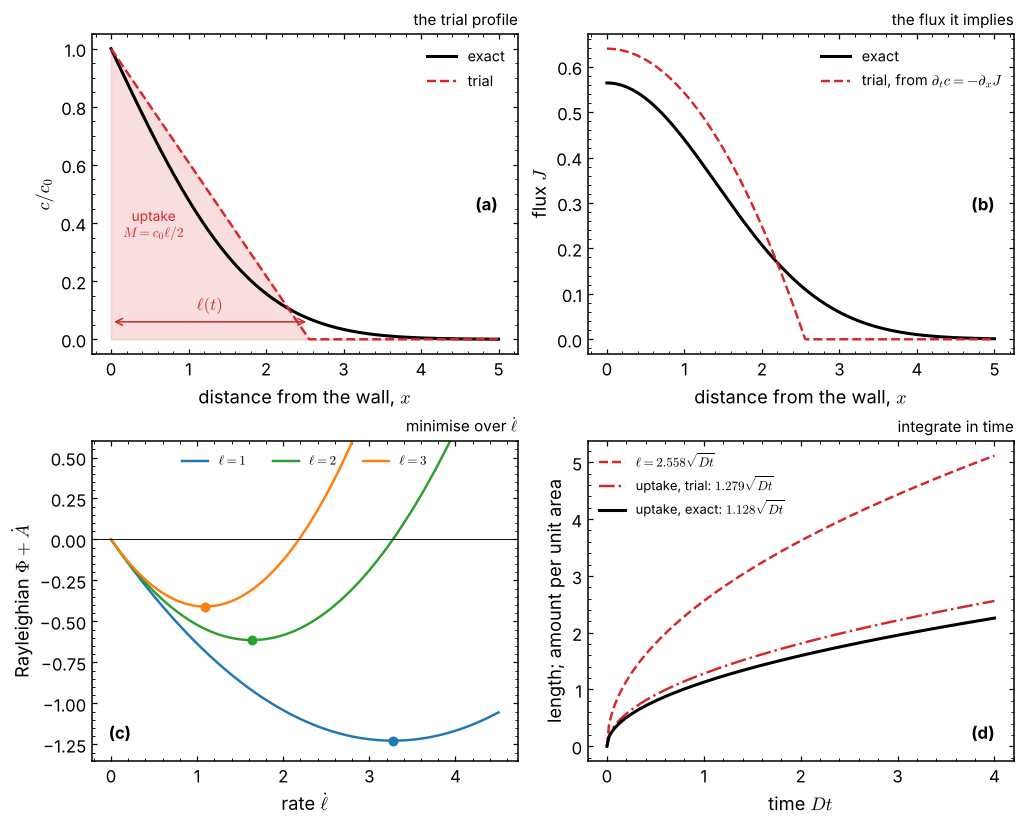

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))
lam1 = math.sqrt(72 / 11)                       # straight line; units D = c0 = k_BT = zeta = 1
xs_ = np.linspace(0, 5, 500)
t_show = 1.0
ell_show = lam1 * math.sqrt(t_show)
ldot_show = ell_show / (2 * t_show)

ax = axes[0, 0]
ax.fill_between(xs_, np.clip(1 - xs_ / ell_show, 0, None), color="C3", alpha=0.15)
ax.plot(xs_, erfc(xs_ / (2 * math.sqrt(t_show))), "k-", lw=2, label="exact")
ax.plot(xs_, np.clip(1 - xs_ / ell_show, 0, None), "--", color="C3", label="trial")
ax.annotate("", xy=(ell_show, 0.06), xytext=(0, 0.06), arrowprops=dict(arrowstyle="<->", color="C3"))
ax.text(ell_show / 2, 0.1, r"$\ell(t)$", color="C3", ha="center")
ax.text(0.55, 0.35, "uptake\n$M = c_0\\ell/2$", color="C3", fontsize=9, ha="center")
ax.set_xlabel("distance from the wall, $x$"); ax.set_ylabel("$c/c_0$"); ax.set_title("the trial profile", loc="right", fontsize=10)
ax.legend(loc="upper right"); on.panel_label(ax, "(a)", x=0.9, y=0.5)

ax = axes[0, 1]
J_trial = np.where(xs_ < ell_show, ldot_show * (ell_show**2 - xs_**2) / (2 * ell_show**2), 0.0)
ax.plot(xs_, np.exp(-xs_**2 / (4 * t_show)) / math.sqrt(math.pi * t_show), "k-", lw=2, label="exact")
ax.plot(xs_, J_trial, "--", color="C3", label=r"trial, from $\partial_tc = -\partial_xJ$")
ax.set_xlabel("distance from the wall, $x$"); ax.set_ylabel(r"flux $J$"); ax.set_title("the flux it implies", loc="right", fontsize=10)
ax.legend(loc="upper right"); on.panel_label(ax, "(b)", x=0.9, y=0.5)

ax = axes[1, 0]
rate = np.linspace(0, 4.5, 300)
for ell_, col in ((1.0, "C0"), (2.0, "C2"), (3.0, "C1")):
    ax.plot(rate, 11 / 96 * ell_ * rate**2 - 0.75 * rate, color=col, label=rf"$\ell = {ell_:g}$")
    best = 36 / (11 * ell_)
    ax.plot(best, 11 / 96 * ell_ * best**2 - 0.75 * best, "o", color=col)
ax.axhline(0, color="k", lw=0.6); ax.set_ylim(-1.35, 0.6)
ax.set_xlabel(r"rate $\dot\ell$"); ax.set_ylabel(r"Rayleighian $\Phi + \dot A$"); ax.set_title(r"minimise over $\dot\ell$", loc="right", fontsize=10)
ax.legend(loc="upper center", ncol=3, fontsize=8.5); on.panel_label(ax, "(c)", x=0.04, y=0.12)

ax = axes[1, 1]
tt_ = np.linspace(0, 4, 200)
ax.plot(tt_, lam1 * np.sqrt(tt_), "--", color="C3", label=r"$\ell = 2.558\sqrt{Dt}$")
ax.plot(tt_, lam1 / 2 * np.sqrt(tt_), "-.", color="C3", label=r"uptake, trial: $1.279\sqrt{Dt}$")
ax.plot(tt_, 2 / math.sqrt(math.pi) * np.sqrt(tt_), "k-", lw=2, label=r"uptake, exact: $1.128\sqrt{Dt}$")
ax.set_xlabel("time $Dt$"); ax.set_ylabel("length; amount per unit area"); ax.set_title("integrate in time", loc="right", fontsize=10)
ax.legend(loc="upper left", fontsize=8.5); on.panel_label(ax, "(d)", x=0.9, y=0.12)
plt.show()

**Figure 5.1.** The four steps of the calculation for the straight-line profile, at
$Dt = 1$. **(a)** The trial profile and its single parameter. **(b)** The flux that
conservation requires when $\ell$ grows; it enters the dissipation function. The
trial puts the flux in roughly the right place but not with the right shape.
**(c)** The Rayleighian as a function of the rate $\dot\ell$, for three values of
$\ell$. Each parabola has its minimum at $\dot\ell = 36D/11\ell$: the longer the
profile, the more it costs to extend it, and the slower it grows. **(d)** Integrating
that rate gives $\ell(t)$ and the uptake.

## 5.3 A family of profiles

A profile that meets the front smoothly should do better. Take

$$ c = c_0\Big(1 - \frac{x}{\ell}\Big)^{n} , $$

with a fixed exponent $n$. The same steps (the cell below carries out the
integrals) give

$$ \Phi = \tfrac12\zeta c_0\,I(n)\,\ell\,\dot\ell^2 , \qquad \dot A = -k_BT c_0\,g(n)\,\dot\ell , $$

$$ I(n) = \frac{5n+6}{(n+1)^2(n+2)(n+3)} , \qquad
   g(n) = \frac{2n+1}{(n+1)^2} , $$

and therefore $\ell = \lambda\sqrt{Dt}$ with $\lambda^2 = 2g/I$, and
$M = [\lambda/(n+1)]\,c_0\sqrt{Dt}$.

In [3]:
n, s, u = sp.symbols("n s u", positive=True)

# J / (c0 ldot) for the profile s**n, s = 1 - u, by integrating dc/dt from u to 1
flux = sp.simplify(sp.integrate(n * s ** (n - 1) * (1 - s), (s, 0, s)))          # as a function of s
I_n = sp.simplify(sp.integrate(sp.expand(flux**2 / s**n), (s, 0, 1)))
g_n = sp.simplify(sp.integrate(s**n - n * s**n * sp.log(s), (s, 0, 1)))
print("J / (c0 ldot) =", sp.factor(flux))
print("I(n) =", sp.factor(I_n))
print("g(n) =", sp.factor(g_n))
assert sp.simplify(I_n - (5 * n + 6) / ((n + 1) ** 2 * (n + 2) * (n + 3))) == 0
assert sp.simplify(g_n - (2 * n + 1) / (n + 1) ** 2) == 0

I_num, g_num = sp.lambdify(n, I_n), sp.lambdify(n, g_n)
lam_of_n = lambda nn: np.sqrt(2 * g_num(nn) / I_num(nn))
exact_uptake = 2 / math.sqrt(math.pi)
xi = np.linspace(0, 9, 9001)                 # xi = x / sqrt(D t)
exact_profile = erfc(xi / 2)


def trial_profile(xi, lam, nn):
    return np.where(xi < lam, (1 - np.minimum(xi / lam, 1.0)) ** nn, 0.0)


def report(label, lam, nn):
    up = lam / (nn + 1)
    print(f"  {label:26s} {nn:6.3f}  {lam:6.3f}    {up:6.4f}   {100 * (up / exact_uptake - 1):+6.1f} %"
          f"      {on.sup_error(trial_profile(xi, lam, nn), exact_profile):.3f}"
          f"        {nn / lam:.3f}        {lam / (2 * (nn + 1)):.3f}")


print("\n  trial                         n    lambda   uptake    error    profile error   flux (gradient)  flux (uptake)")
for nn in (1, 2, 3):
    report(f"fixed exponent n = {nn}", lam_of_n(nn), nn)
print(f"  {'exact':26s}                  {exact_uptake:6.4f}                              "
      f"{1 / math.sqrt(math.pi):.3f}        {1 / math.sqrt(math.pi):.3f}")
print(f"\nlambda^2 for n = 1, 2, 3: {[sp.nsimplify(2 * g_n.subs(n, k) / I_n.subs(n, k)) for k in (1, 2, 3)]}")

J / (c0 ldot) = -s**n*(n*s - n - 1)/(n + 1)
I(n) = (5*n + 6)/((n + 1)**2*(n + 2)*(n + 3))
g(n) = (2*n + 1)/(n + 1)**2

  trial                         n    lambda   uptake    error    profile error   flux (gradient)  flux (uptake)
  fixed exponent n = 1        1.000   2.558    1.2792    +13.4 %      0.135        0.391        0.640
  fixed exponent n = 2        2.000   3.536    1.1785     +4.4 %      0.043        0.566        0.589
  fixed exponent n = 3        3.000   4.472    1.1180     -0.9 %      0.023        0.671        0.559
  exact                                       1.1284                              0.564        0.564

lambda^2 for n = 1, 2, 3: [72/11, 25/2, 20]


The amount taken up improves from $+13$ % ($n = 1$) to $+4$ % ($n = 2$) and
$-1$ % ($n = 3$). The largest error of the profile improves as well, from 0.13 to
0.02 (in units of $c_0$).

The last two columns are a diagnostic that needs no exact solution. The flux at the
wall can be computed from a trial solution in two ways: from the gradient at the
wall, $-D\,\partial c/\partial x = (n/\lambda)\,c_0\sqrt{D/t}$, or from the rate of
uptake, $dM/dt = [\lambda/2(n+1)]\,c_0\sqrt{D/t}$. For the exact solution they are
equal. For a trial solution they are not, because a trial solution satisfies the
diffusion equation only on average, not point by point. The disagreement is a
measure of how far the trial form is from a solution: large for $n = 1$ (0.39
against 0.64), small for $n = 2$ (0.57 against 0.59). Of the two, the rate of uptake
is the more reliable (for $n = 2$ the gradient happens to be very accurate, but over
the three profiles it ranges from 31 % low to 19 % high, against 13 % for the rate
of uptake). The rate of uptake follows from the kinetic equation of the parameter,
whereas the gradient at the wall depends on the detailed shape that was
put in by hand.

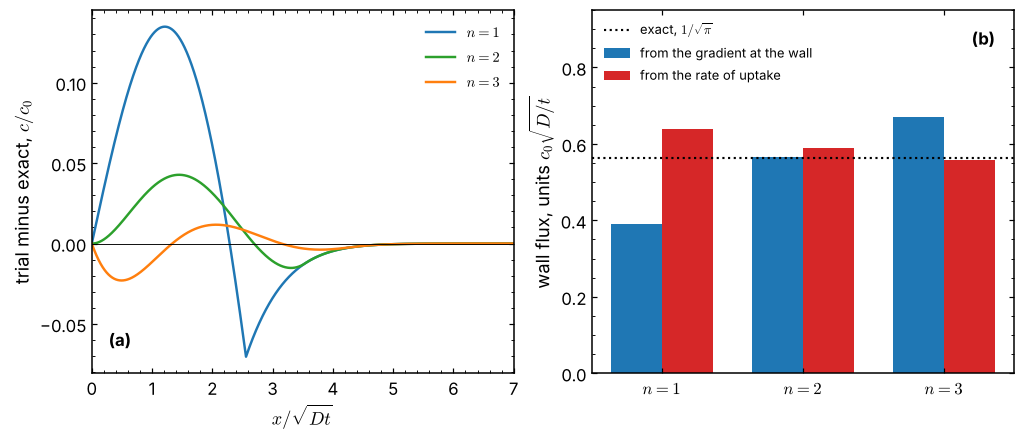

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))

for nn, col in ((1, "C0"), (2, "C2"), (3, "C1")):
    ax1.plot(xi, trial_profile(xi, lam_of_n(nn), nn) - exact_profile, color=col, label=rf"$n = {nn}$")
ax1.axhline(0, color="k", lw=0.6)
ax1.set_xlim(0, 7); ax1.set_xlabel(r"$x/\sqrt{Dt}$"); ax1.set_ylabel(r"trial minus exact, $c/c_0$")
ax1.legend(loc="upper right"); on.panel_label(ax1, "(a)", x=0.04, y=0.12)

pos = np.arange(3)
grad = [nn / lam_of_n(nn) for nn in (1, 2, 3)]
upt = [lam_of_n(nn) / (2 * (nn + 1)) for nn in (1, 2, 3)]
ax2.bar(pos - 0.18, grad, 0.36, color="C0", label="from the gradient at the wall")
ax2.bar(pos + 0.18, upt, 0.36, color="C3", label="from the rate of uptake")
ax2.axhline(1 / math.sqrt(math.pi), color="k", ls=":", lw=1.4, label=r"exact, $1/\sqrt{\pi}$")
ax2.set_xticks(pos); ax2.set_xticklabels(["$n = 1$", "$n = 2$", "$n = 3$"]); ax2.tick_params(axis="x", which="minor", bottom=False, top=False)
ax2.set_ylim(0, 0.95); ax2.set_ylabel(r"wall flux, units $c_0\sqrt{D/t}$")
ax2.legend(loc="upper left", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.9, y=0.95)
plt.show()

**Figure 5.2.** **(a)** Error of the trial profiles. The straight line is too high
through most of its range and misses the tail entirely; the cubic stays within 0.02
of the exact profile. **(b)** The wall flux computed in two ways from each trial
solution. The disagreement between the two bars is a measure of the quality of the
trial that requires no exact solution. The estimate from the rate of uptake stays
within 13 % of the exact value for all three profiles; the estimate from the
gradient ranges from 31 % low to 19 % high.

## 5.4 Letting the shape evolve

Why choose $n$ at all? Make it a second parameter, $n(t)$, and let Eq. (5.1) decide.
There are now two rates, $\dot\ell$ and $\dot n$, a $2\times2$ friction matrix, and two
forces, $-\partial A/\partial\ell = k_BT c_0\,g(n)$ and
$-\partial A/\partial n = k_BT c_0\,\ell\,g'(n)$. The friction matrix is

$$ \tilde\zeta_{\alpha\beta} = \zeta\int \frac{J_\alpha J_\beta}{c}\,dx , \qquad
   J_\alpha(x) = \int_x^\ell \frac{\partial c}{\partial a_\alpha}\,dx' , $$

where $J_\alpha$ is the flux produced by a unit rate of parameter $a_\alpha$.
`on.friction_matrix_1d` evaluates these integrals on a grid for any trial profile,
given the derivatives of the profile with respect to its parameters. It reproduces
$I(n)$ for the element $\tilde\zeta_{\ell\ell}$:

In [5]:
def friction(ell, nn, points=4001):
    """Friction matrix of (ell, n) for c = (1 - x/ell)**n  (units c0 = zeta = 1)."""
    x = np.linspace(0, ell, points)
    sx = 1 - x / ell
    c = sx**nn
    dc_dl = nn * sx ** (nn - 1) * x / ell**2
    dc_dn = np.where(sx > 0, c * np.log(np.maximum(sx, 1e-300)), 0.0)
    return on.friction_matrix_1d(x, c, [dc_dl, dc_dn])


g_prime = sp.lambdify(n, sp.diff(g_n, n))
print(f"zeta_ll / ell at n = 2: {friction(1.0, 2.0)[0, 0]:.6f}   (I(2) = 4/45 = {4/45:.6f})")


def rates(t, y):
    ell, nn = y
    return np.linalg.solve(friction(ell, nn), [g_num(nn), ell * g_prime(nn)])


t0, t1 = 1e-3, 1e2
t_out = np.logspace(-3, 2, 61)
histories = {}
for n_start in (1.5, 3.0, 6.0):
    sol = solve_ivp(rates, (t0, t1), [lam_of_n(n_start) * math.sqrt(t0), n_start], t_eval=t_out, rtol=1e-8, atol=1e-10)
    histories[n_start] = sol.y
    print(f"start n = {n_start}:  at t = 100,  n = {sol.y[1, -1]:.4f},  ell / sqrt(D t) = {sol.y[0, -1] / 10:.4f}")


# the fixed point directly: ndot = 0 with ell = lambda sqrt(D t)
def residual(nn):
    Z = friction(1.0, nn, points=20001)
    return Z[0, 1] * g_num(nn) / Z[0, 0] - g_prime(nn)


n_star = brentq(residual, 2.0, 6.0)
lam_star = lam_of_n(n_star)
print(f"\nfixed point: n* = {n_star:.4f},  lambda* = {lam_star:.4f}")
print("\n  trial                         n    lambda   uptake    error    profile error   flux (gradient)  flux (uptake)")
report("exponent free, n -> n*", lam_star, n_star)

zeta_ll / ell at n = 2: 0.088889   (I(2) = 4/45 = 0.088889)
start n = 1.5:  at t = 100,  n = 3.6535,  ell / sqrt(D t) = 5.0747


start n = 3.0:  at t = 100,  n = 3.6535,  ell / sqrt(D t) = 5.0747
start n = 6.0:  at t = 100,  n = 3.6535,  ell / sqrt(D t) = 5.0747

fixed point: n* = 3.6535,  lambda* = 5.0747

  trial                         n    lambda   uptake    error    profile error   flux (gradient)  flux (uptake)
  exponent free, n -> n*      3.653   5.075    1.0905     -3.4 %      0.040        0.720        0.545


Whatever exponent the profile starts with, it relaxes to the same value,
$n^* = 3.65$, with $\lambda^* = 5.07$: a self-similar profile selected by the
principle, with nothing put in by hand except the family. The initial condition is
forgotten, as it is in the exact problem.

The selected profile takes up $1.091\,c_0\sqrt{Dt}$, which is 3.4 % below the exact
value. This is a good result, but it is not better than the fixed exponent $n = 3$
($-0.9$ %), its largest profile error, 0.04, is not better either, and its two
estimates of the wall flux (0.72 and 0.55) disagree more than those of $n = 2$. That
deserves a comment, because it contradicts a natural expectation.

Adding a parameter enlarges the family, and so lowers the minimum of the
Rayleighian at each instant. It does not follow that every quantity of interest
improves. The Rayleighian weighs errors in its own way (through the dissipation
function, that is, by $J^2/c$), and the family here has a defect that no exponent
removes: the trial profile ends at a finite distance, while the exact one has a
tail. The exponent $n = 3$ happens to give a good uptake; the principle, asked to
choose, compromises between the wall and the front. A trial solution is only as
good as its family. The remedy for a poor family is a better family, not more
faith in the method.

## 5.5 The time-integrated form

Section 5.4 chose the exponent by turning it into a dynamical variable. There is a
second way, which looks at the whole path at once. For any path $x(t)$, define

$$ O[x(t)] = \int_0^T \big[ \Phi(\dot x) + \dot A + \Phi^*(x) \big]\,dt , \qquad
   \Phi^* = \frac12\sum_{i,j}\mu_{ij}\frac{\partial A}{\partial x_i}\frac{\partial A}{\partial x_j} . \tag{5.2} $$

Let $\dot x^*_i = -\sum_j\mu_{ij}\,\partial A/\partial x_j$ be the rates that the
kinetic equations prescribe at the state $x$. Since $\sum_j\zeta_{ij}\dot x^*_j =
-\partial A/\partial x_i$, the integrand is a perfect square,

$$ \Phi(\dot x) + \dot A + \Phi^*(x) = \frac12\sum_{i,j}\zeta_{ij}\,(\dot x_i - \dot x^*_i)(\dot x_j - \dot x^*_j) \;\ge\; 0 . $$

The integral is zero for the path that obeys the kinetic equations and positive
for every other path. It is the integral introduced by Onsager and Machlup in 1953,
and its use for selecting trial solutions is due to Doi, Zhou, Di and Xu (2019): of
two trial paths, the one with the smaller integral is to be preferred, and the
comparison needs no knowledge of the exact solution.

For diffusion, $\Phi^* = (2\zeta)^{-1}\int c\,(\partial\mu/\partial x)^2 dx =
(k_BT)^2(2\zeta)^{-1}\int (\partial c/\partial x)^2/c\;dx$. For the self-similar trial
path $c = c_0(1 - x/\lambda\sqrt{Dt})^n$, all three terms are proportional to
$k_BT c_0\sqrt{D/t}$:

$$ \Phi + \dot A + \Phi^* = k_BT c_0\sqrt{\frac{D}{t}}\;\;b(\lambda, n) , \qquad
   b(\lambda, n) = \frac{I(n)\,\lambda^3}{8} - \frac{g(n)\,\lambda}{2} + \frac{n^2}{2\lambda\,(n-1)} . \tag{5.3} $$

The last term requires $n > 1$: for the straight line the integral of
$(\partial c/\partial x)^2/c$ diverges at the front, logarithmically. (Doi and
co-workers met the same divergence for profiles that reach zero with a finite
slope, in their example of diffusion from a point source, and handled it with a
cut-off.) Minimising the function $b(\lambda, n)$ over both arguments selects one
member of the family.

In [6]:
def b(lam, nn):
    return I_num(nn) * lam**3 / 8 - g_num(nn) * lam / 2 + nn**2 / (2 * lam * (nn - 1))


best = minimize(lambda p: b(*p) if p[1] > 1.01 and p[0] > 0 else 1e9, [4.5, 3.0], method="Nelder-Mead",
                options={"xatol": 1e-9, "fatol": 1e-14})
lam_om, n_om = best.x
print(f"minimum of b: lambda = {lam_om:.4f}, n = {n_om:.4f},  b = {best.fun:.5f}")
print(f"for comparison, the fixed point of Section 5.4: lambda* = {lam_star:.4f}, n* = {n_star:.4f},"
      f"  b = {b(lam_star, n_star):.5f}")
for nn in (2, 3):
    print(f"fixed exponent n = {nn}:  b = {b(lam_of_n(nn), nn):.5f}")

# the same three terms for the exact solution, c = erfc(xi/2), by quadrature
c_ex = lambda z: erfc(z / 2)
dc_ex = lambda z: -math.exp(-z * z / 4) / math.sqrt(math.pi)
phi_star = 0.5 * quad(lambda z: dc_ex(z) ** 2 / c_ex(z), 0, 30)[0]
a_dot = -0.5 * quad(lambda z: c_ex(z) * (1 - math.log(c_ex(z))) if c_ex(z) > 0 else 0.0, 0, 30)[0]
print(f"exact solution: Phi = Phi* = {phi_star:.5f},  Adot = {a_dot:.5f},  sum = {2 * phi_star + a_dot:.1e}")

print("\n  trial                         n    lambda   uptake    error    profile error   flux (gradient)  flux (uptake)")
report("minimum of b", lam_om, n_om)

minimum of b: lambda = 5.1760, n = 3.7511,  b = 0.00890
for comparison, the fixed point of Section 5.4: lambda* = 5.0747, n* = 3.6535,  b = 0.00897
fixed exponent n = 2:  b = 0.07464
fixed exponent n = 3:  b = 0.01398
exact solution: Phi = Phi* = 0.49067,  Adot = -0.98134,  sum = -1.1e-16

  trial                         n    lambda   uptake    error    profile error   flux (gradient)  flux (uptake)
  minimum of b                3.751   5.176    1.0894     -3.5 %      0.041        0.725        0.545


The two ways of choosing the exponent agree closely: $n = 3.75$, $\lambda = 5.18$
from the time-integrated form, against $n^* = 3.65$, $\lambda^* = 5.07$ from the
kinetic equations. Both lie in a shallow valley of $b(\lambda, n)$ (Figure 5.3d).
For the exact solution the three terms cancel, as they must: $\Phi = \Phi^* =
-\tfrac12\dot A$.

## 5.6 What to trust in a trial solution

The experience of this chapter, which the later chapters will put to further
tests, can be put in a few statements.

| Trial | $n$ | $\lambda$ | $M/c_0\sqrt{Dt}$ | Error |
|---|---|---|---|---|
| straight line | 1 | 2.558 | 1.279 | $+13.4$ % |
| fixed exponent | 2 | 3.536 | 1.179 | $+4.4$ % |
| fixed exponent | 3 | 4.472 | 1.118 | $-0.9$ % |
| exponent free (Section 5.4) | 3.653 | 5.075 | 1.091 | $-3.4$ % |
| time-integrated form (Section 5.5) | 3.751 | 5.176 | 1.089 | $-3.5$ % |
| exact | | | 1.128 | |

* **Scaling laws are safe.** Every trial gave $\sqrt{Dt}$. An exponent that follows
  from the dimensions of the two functions does not depend on the quality of the
  trial form.
* **Numerical coefficients are approximate**, typically to some per cent for a
  reasonable family, and they are not bounds: the uptake is overestimated by some
  trials and underestimated by others. (The flow rate of Section 1.3 was a bound
  because it was the minimum value of $R$ itself; the uptake is not.)
* **Integrated quantities are usually better than local ones.** Over the trials of
  this chapter the uptake is within 13 %, while the gradient at the wall is off by
  up to 31 %. Single cases can go the other way: for $n = 2$ the wall gradient
  happens to be nearly exact.
* **Internal consistency is a free test.** Compute one quantity in two ways; if the
  answers differ widely, the family is poor.
* **More parameters help only if the family can represent the solution.** The
  principle selects the best member of the family; it cannot repair the family.
* **When in doubt, check one case against a full solution.** That is the practice of
  this book.

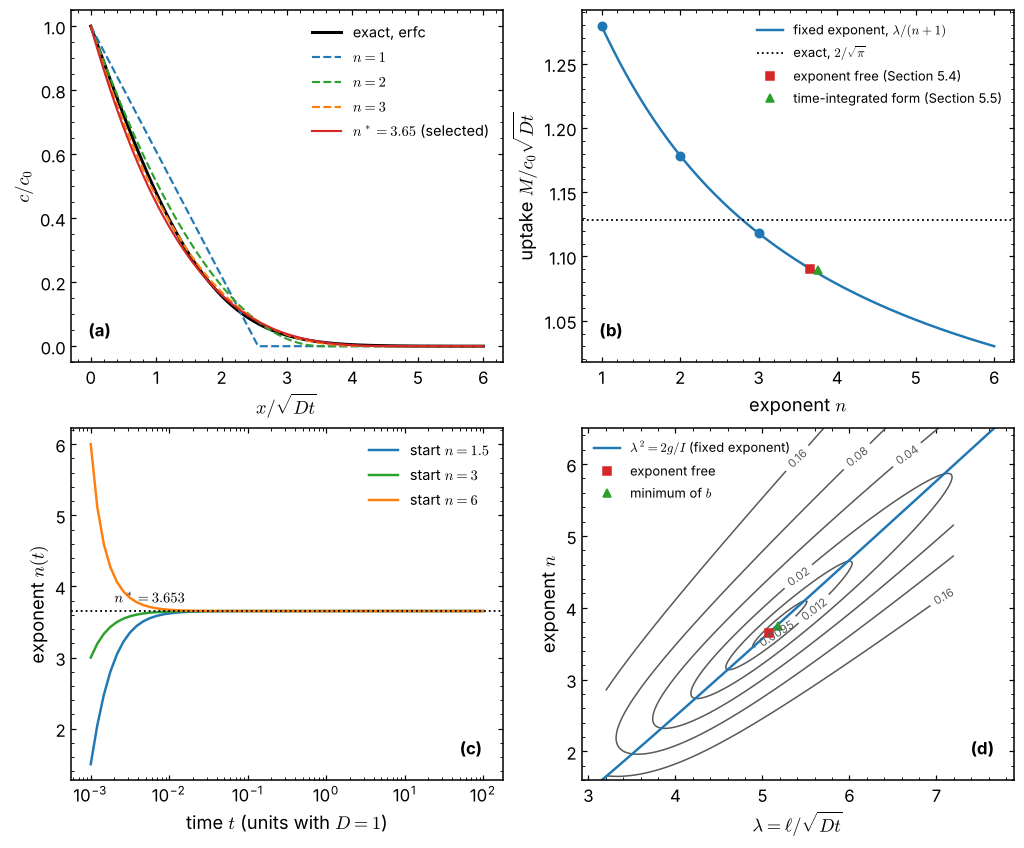

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))

ax = axes[0, 0]
xp = np.linspace(0, 6, 600)
ax.plot(xp, erfc(xp / 2), "k-", lw=2, label="exact, erfc")
for nn, lam, c, ls in ((1, lam_of_n(1), "C0", "--"), (2, lam_of_n(2), "C2", "--"), (3, lam_of_n(3), "C1", "--"),
                       (n_star, lam_star, "C3", "-")):
    lab = rf"$n = {nn}$" if nn in (1, 2, 3) else rf"$n^* = {nn:.2f}$ (selected)"
    ax.plot(xp, trial_profile(xp, lam, nn), ls, color=c, lw=1.4, label=lab)
ax.set_xlabel(r"$x/\sqrt{Dt}$"); ax.set_ylabel("$c/c_0$")
ax.legend(loc="upper right"); on.panel_label(ax, "(a)", x=0.04, y=0.12)

ax = axes[0, 1]
ns = np.linspace(1, 6, 200)
ax.plot(ns, lam_of_n(ns) / (ns + 1), "-", color="C0", label=r"fixed exponent, $\lambda/(n+1)$")
ax.axhline(exact_uptake, color="k", ls=":", lw=1.2, label=r"exact, $2/\sqrt{\pi}$")
for nn in (1, 2, 3):
    ax.plot(nn, lam_of_n(nn) / (nn + 1), "o", color="C0")
ax.plot(n_star, lam_star / (n_star + 1), "s", color="C3", label="exponent free (Section 5.4)")
ax.plot(n_om, lam_om / (n_om + 1), "^", color="C2", label="time-integrated form (Section 5.5)")
ax.set_xlabel("exponent $n$"); ax.set_ylabel(r"uptake $M/c_0\sqrt{Dt}$")
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(b)", x=0.04, y=0.12)

ax = axes[1, 0]
for n_start, c in ((1.5, "C0"), (3.0, "C2"), (6.0, "C1")):
    ax.semilogx(t_out, histories[n_start][1], color=c, label=f"start $n = {n_start:g}$")
ax.axhline(n_star, color="k", ls=":", lw=1.2)
ax.text(2e-3, n_star + 0.12, rf"$n^* = {n_star:.3f}$", fontsize=9.5)
ax.set_xlabel("time $t$ (units with $D = 1$)"); ax.set_ylabel("exponent $n(t)$")
ax.legend(loc="upper right"); on.panel_label(ax, "(c)", x=0.9, y=0.12)

ax = axes[1, 1]
LAM, NN = np.meshgrid(np.linspace(3.2, 7.2, 200), np.linspace(1.6, 6.5, 200))
cs = ax.contour(LAM, NN, b(LAM, NN), levels=[0.0095, 0.012, 0.02, 0.04, 0.08, 0.16], colors="0.35", linewidths=1)
ax.clabel(cs, fmt="%.3g", fontsize=7.5)
nline = np.linspace(1.6, 6.5, 100)
ax.plot(lam_of_n(nline), nline, "-", color="C0", label=r"$\lambda^2 = 2g/I$ (fixed exponent)")
ax.plot(lam_star, n_star, "s", color="C3", label="exponent free")
ax.plot(lam_om, n_om, "^", color="C2", label="minimum of $b$")
ax.set_xlabel(r"$\lambda = \ell/\sqrt{Dt}$"); ax.set_ylabel("exponent $n$")
ax.legend(loc="upper left", fontsize=8.5); on.panel_label(ax, "(d)", x=0.9, y=0.12)
plt.show()

**Figure 5.3.** **(a)** Diffusion into a half-space: exact profile and trial profiles
$c_0(1 - x/\ell)^n$ with $\ell = \lambda\sqrt{Dt}$ given by the Onsager principle.
**(b)** Amount taken up, as a function of the exponent of the trial profile. The
square is the exponent selected when $n$ is a dynamical variable, the triangle the
one selected by the time-integrated form. **(c)** With $n$ free, the exponent
relaxes to the same value from any start. **(d)** Contours of the function
$b(\lambda, n)$ of Eq. (5.3), which vanishes for the exact solution. The line is the
result of Section 5.3 for each fixed exponent.

## Summary

* Restricting the motion to a family with parameters $a_\alpha(t)$ and minimising
  the Rayleighian over their rates gives kinetic equations of Onsager's form for the
  parameters, with a reduced friction matrix. The approximate motion always lowers
  the free energy.
* For diffusion into a half-space a straight-line profile gives the exact
  $\sqrt{Dt}$ law and the uptake to 13 %; smoother profiles give it to a few per
  cent.
* A shape parameter can be made a dynamical variable, or chosen by minimising the
  Onsager–Machlup integral (5.2) along the path. The two selections agree closely.
* Scaling laws from a trial solution are reliable, coefficients are approximate and
  are not bounds, integrated quantities are usually better than local ones, and the quality
  of the result is limited by the family.

## Exercises

Sample solutions are in [`solutions/part1_principle/05_solutions.ipynb`](../../solutions/part1_principle/05_solutions.ipynb).

1. **An exponential profile.** Take $c = c_0\,e^{-x/\ell(t)}$, which has a tail but the
   wrong one. Show that $\Phi = \tfrac52\zeta c_0\,\ell\dot\ell^2$ and
   $\dot A = -2k_BTc_0\dot\ell$, hence $\ell^2 = \tfrac45Dt$ and
   $M = 0.894\,c_0\sqrt{Dt}$, which is 21 % low. Check the friction coefficient with
   `on.friction_matrix_1d`. Why is this trial worse than the straight line?
2. **A case where the trial is exact.** A pulse of $N$ particles spreads on an
   infinite line. Take a Gaussian of width $\sigma(t)$. Show that
   $\Phi = \tfrac12\zeta N\dot\sigma^2$ and $A = -Nk_BT\ln\sigma + {\rm const}$, so that
   $\sigma^2 = \sigma_0^2 + 2Dt$, the exact result. What property of the trial family
   makes it exact?
3. **The quadratic profile by hand.** Carry out the steps of Section 5.2 for $n = 2$
   and obtain $\lambda^2 = 25/2$.
4. **Repelling particles.** Repeat Section 5.2 for the non-ideal solution of
   Section 4.3, with a straight-line profile. The kinetic equation still gives
   $\ell \propto \sqrt t$; find how the coefficient depends on $Bc_0$, and compare with a
   numerical solution of the diffusion equation with $D(c) = D\,(1 + Bc)$.

## Suggested references

* M. Doi, *Soft Matter Physics* (Oxford University Press, 2013).
* J. Crank, *The Mathematics of Diffusion*, 2nd ed. (Oxford University Press, 1975).
* B. A. Finlayson, *The Method of Weighted Residuals and Variational Principles* (Academic Press, 1972; SIAM, 2014).
* M. Doi, "Onsager principle as a tool for approximation", *Chin. Phys. B* **24**, 020505 (2015).
* M. Doi, J. Zhou, Y. Di and X. Xu, "Application of the Onsager-Machlup integral in solving dynamic equations in nonequilibrium systems", *Phys. Rev. E* **99**, 063303 (2019).
* L. Onsager and S. Machlup, "Fluctuations and irreversible processes", *Phys. Rev.* **91**, 1505 (1953).

---

**Previous:** [4. From the principle to field equations](04_field_equations.ipynb)